# Анализ температуры многолетних мерзлых пород в России

Автор: Егор Калитин, Факультет географии и геоинформационных технологий НИУ ВШЭ, БГЕО252, октябрь 2026 года

### Ну лёд и лёд, чё анализировать-то?

Под вечной мерзлотой понимают горные породы, которые имеют отрицательную температуру и содержат в составе лёд в течение минимум 2 лет подряд; по факту же лёд в грунте может оставаться в замерзшем состоянии тысячелетия, формируя термокарстовые формы рельефа. **В России 65% территории находится в зоне многолетних мёрзлых грунтов.**

Рост среднегодовой температуры из-за глобального изменения климата выводит из равновесия систему многолетних мерзлых грунтов. Изменение рельефа (термокарстовые процессы), такие как проседание, пучение, оползание грунта могут разрушать уже существующую и мешать строительству ещё не построенной инфраструктуры. 

Наблюдение и анализ динамики изменений температуры грунта помогут грамотно планировать инфраструктурные проекты в российской Арктике и других затронутых частях страны. 

### А данные откуда?

> «Температура многолетнемерзлых грунтов в России с 2022 года» // Росгидромет, ААНИИ; обработка: «Если быть точным», 2026. URL: https://tochno.st/datasets/permafrost

**Если быть точным** (https://tochno.st/) - российская платформа открытых данных и аналитический проект фонда «Нужна помощь», которая собирает данные по социально значимым проблемам сами или обрабатывают чужие данные. 

Рассматриваемый набор данных охватывает период с 2022 по 2026 год с данными о температуре грунта на разных глубинах в скважинах государственной сети фонового мониторинга состояния многолетней мерзлоты (ГСФМ СММ), которую ведет Росгидромет. В наборе 77 пунктов наблюдения в 12 субъектах России, больше всего — в Республике Саха (Якутия) (31) и Ямало-Ненецком автономном округе (15).

Набор доступен для работы в форматах Parquet и CSV (кодировка: «UTF-8», разделитель: «,», архив gzip); широкая таблица и справочник пунктов — также в XLSX. 

### Кто будет этим пользоваться?

Учёные-гляциологи,-геоморфологи, -почвоведы, -геоэкологи, студенты географических, геологических и экологических направлений, урбанисты, аналитики и любые желающие прикоснуться к проблеме глобального изменения климата и его влияния на Россию.

# Код и циферки

## 1. Подготовка данных

Импортируем библиотеку pandas, чтобы работали таблицы и библиотеки time, чтобы python корректно считывал даты, а также matplotlib и cartopy для отображения карт.

In [172]:
import pandas as pd
import time
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

**Важно подготовить правильные данные!** Используемый набор данных поставляется в формате .csv с разделителем-запятой.

Прочитаем данные (может занять некоторое время): 

In [177]:
# читаем csv-файлы 
df_stations = pd.read_csv('data/permafrost_stations.csv')
df_long = pd.read_csv('data/permafrost_temperature_long.csv')
df_wide = pd.read_csv('data/permafrost_temperature_wide.csv')

# проверяем, что всё загрузилось успешно
print("Справочник станций загружен. Строк:", len(df_stations))
print("Длинная таблица температур загружена. Строк:", len(df_long))
print("Широкая таблица температур загружена. Строк:", len(df_wide))

Справочник станций загружен. Строк: 77
Длинная таблица температур загружена. Строк: 6760318
Широкая таблица температур загружена. Строк: 213402


А что в колонках? Смотрим:

In [174]:
# посмотрим колонки длинной таблицы температур
print("Колонки в df_long:")
print(df_long.columns.tolist()) 

Колонки в df_long:
['indicator_code', 'indicator_name', 'depth_m', 'object_name', 'object_level', 'object_code', 'datetime', 'year', 'indicator_value', 'indicator_unit', 'source']


Откроем первые пару строчек таблиц. Во второй таблице более 6,5 миллионов записей, и если открыть её целиком, компьютер крашнется :(

P.S. я пытался

In [178]:
# Выводим первые строчки справочника
display(df_stations.head(1))
display(df_long.head(1))

,object_code,object_name,object_name_en,object_level,region,weather_station,well_number,lat,lon,opening_date,online,description,description_en,source
0,76d174db-5a11-4e9b-8341-3c9abbfe2df6,А Покровск,Pokrovsk №015-24856-14,Пункт наблюдения,Республика Саха (Якутия),А Покровск,001-015-24856-14,61.4949,129.1664,2023-10-31,True,Пункт мониторинга Покровск расположен на левом...,The Pokrovsk monitoring point is located on th...,"ГСФМ СММ, permafrost.aari.ru"


,indicator_code,indicator_name,depth_m,object_name,object_level,object_code,datetime,year,indicator_value,indicator_unit,source
0,ground_temperature,Температура грунта,0.0,А Покровск,Пункт наблюдения,76d174db-5a11-4e9b-8341-3c9abbfe2df6,2023-11-29 06:00:00,2023,-15.76,°C,"ГСФМ СММ, permafrost.aari.ru"


А если данные кривые? Посмотрим, сколько на самом точек наблюдения (метеостанций) записано в наборе данных:

In [179]:
# проверим, сколько уникальных станций представлено в измерениях
unique_stations_in_long = df_long['object_code'].nunique()
print(f"\nКоличество уникальных станций в таблице температур: {unique_stations_in_long}")


Количество уникальных станций в таблице температур: 77


Набор собирает все опубликованные измерения 77 пунктов, как и указано в документации.

Всё в порядке, переходим к действиям)

## 2. Построение карты метеостанций

Было бы славно понять, где находятся точки наблюдения в наборе данных. Как мы увидели ранее, в таблице **permafrost_stations** есть географические координаты: столбцы **lat** и **lon**. Именно с помощью них будем определять местоположение метеостанции.

Чтобы было красиво, зададим коническую проекцию для России, границы отображения карты, а также настроим дизайн.

In [180]:
def plot_permafrost_map(df_stations):
    """
    Plot permafrost monitoring stations in Russia on a Lambert Conformal map.
    
    Parameters:
    - df_stations (pd.DataFrame): DataFrame containing 'lon' and 'lat' columns.
    """
    #создаем фигуру и задаем проекцию (Lambert Conformal, хорошо подходящая для России)
    fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.LambertConformal(central_longitude=105.0, central_latitude=60.0)})

    #устанавливаем границы отображения карты (охватываем территорию России)
    ax.set_extent([30, 180, 40, 80], crs=ccrs.PlateCarree())

    #добавляем географические элементы (береговая линия, границы государств, суша, океаны)
    ax.add_feature(cfeature.LAND, facecolor='#f5f5f5')
    ax.add_feature(cfeature.OCEAN, facecolor='#e0f3f8')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='black')
    ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.5)
    ax.add_feature(cfeature.LAKES, facecolor='#e0f3f8', edgecolor='black', linewidth=0.5)

    #рисуем координатную сеткц
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
    gl.top_labels = False
    gl.right_labels = False

    #наносим точки станций из датафрейма df_stations
    #используем долготу (lon) и широту (lat)
    scatter = ax.scatter(
        df_stations['lon'], 
        df_stations['lat'], 
        color='red', 
        s=40, # размер маркера
        marker='o', 
        edgecolor='darkred',
        linewidth=1,
        transform=ccrs.PlateCarree(),
        label='Метеостанции / Скважины')

    # Заголовок и оформление
    plt.title('Пункты мониторинга температуры мерзлоты в России (77 станций)', fontsize=16, pad=20)
    plt.legend(loc='lower left')

    # Показываем карту
    plt.show()

Вызываем функцию и получаем карту:

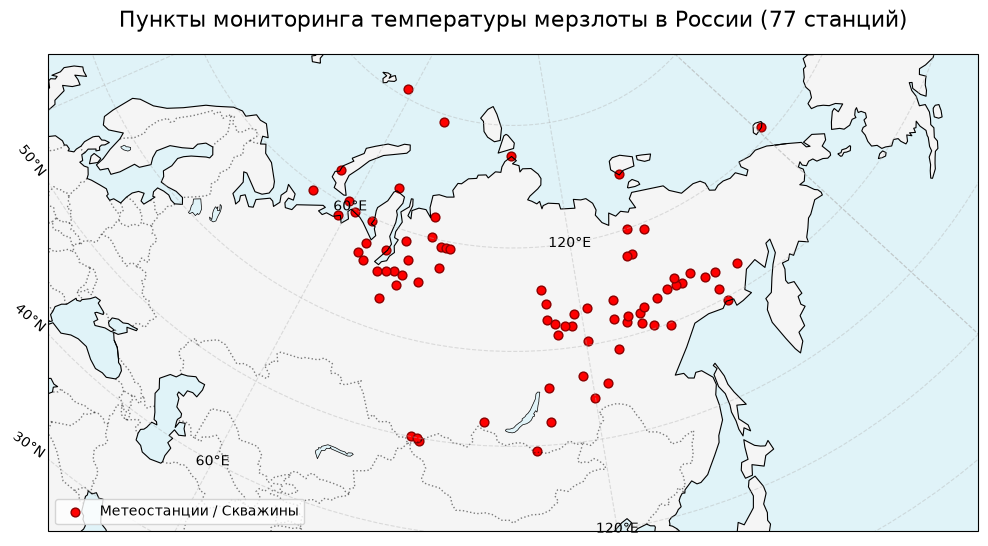

In [181]:
plot_permafrost_map(df_stations)

~~ААА Крокодил в ванной~~ всмысле как много многолетних мерзлых грунтов в России!

## 3. Установка фильтров для поиска

### 3.1. Фильтр по коду метеостанции

Из 77 метеостанций было бы здорово иметь возможность выбирать конкретную. Каждая метеостанция имеет свой код пункта наблюдения (UUID) - универсальный уникальный код из цифр и букв, который записан в табличках csv. К примеру, код для пункта наблюдения А Покровск - **76d174db-5a11-4e9b-8341-3c9abbfe2df6**. В функции выбора пользователь подаёт на ввод этот код (выбирает нужную ему метеостанцию), а на выход получает справочную информацию о пункте наблюдения:

In [182]:
def select_station_interactive(df_stations):
    """
    Interactively select a meteorological station or borehole by entering 
    its object_code via input().
    
    Parameters:
    - df_stations (pd.DataFrame): DataFrame containing stations metadata.
    
    Returns:
    - str: Selected object_code, or None if not found.
    """
    # Запрашиваем код станции у пользователя через input()
    object_code = input("Введите object_code станции: ").strip()
    
    # Ищем станцию по заданному коду
    station_row = df_stations[df_stations['object_code'] == object_code]
    
    if station_row.empty:
        print(f"Станция с кодом '{object_code}' не найдена. Проверьте правильность ввода.")
        return None
    
    # Извлекаем информацию для наглядности
    station_info = station_row.iloc[0]
    
    print(f"\nВыбранная станция:")
    print(f"Код объекта: {station_info.get('object_code', 'N/A')}")
    print(f"Название: {station_info.get('object_name', 'N/A')}")
    print(f"Регион: {station_info.get('region', 'N/A')}")
    print(f"Координаты: lat {station_info.get('lat', 'N/A')}, lon {station_info.get('lon', 'N/A')}")
    
    return object_code

In [183]:
selected_code = select_station_interactive(df_stations) #попробуйте ввести 76d174db-5a11-4e9b-8341-3c9abbfe2df6

Введите object_code станции:  76d174db-5a11-4e9b-8341-3c9abbfe2df6



Выбранная станция:
Код объекта: 76d174db-5a11-4e9b-8341-3c9abbfe2df6
Название: А Покровск
Регион: Республика Саха (Якутия)
Координаты: lat 61.4949, lon 129.1664


### 3.2. Расположение выбранной станции

После выбора станции можно визуализировать конкретный пункт наблюдения на карте России:

In [184]:
def plot_selected_station_on_map(df_stations, selected_code):
    """
    Plot all permafrost monitoring stations on a map and highlight the selected station.
    
    Parameters:
    - df_stations (pd.DataFrame): DataFrame containing stations metadata.
    - selected_code (str): Object code of the station to highlight.
    """
    fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.LambertConformal(central_longitude=105.0, central_latitude=60.0)})

    #Устанавливаем границы отображения карты
    ax.set_extent([30, 180, 40, 80], crs=ccrs.PlateCarree())

    #Добавляем географические элементы
    ax.add_feature(cfeature.LAND, facecolor='#f5f5f5')
    ax.add_feature(cfeature.OCEAN, facecolor='#e0f3f8')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='black')
    ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.5)
    ax.add_feature(cfeature.LAKES, facecolor='#e0f3f8', edgecolor='black', linewidth=0.5)

    #Сетка координат
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
    gl.top_labels = False
    gl.right_labels = False

    #Рисуем все остальные станции (серые точки)
    other_stations = df_stations[df_stations['object_code'] != selected_code]
    ax.scatter(
        other_stations['lon'], 
        other_stations['lat'], 
        color='gray', 
        s=30, 
        alpha=0.6, 
        transform=ccrs.PlateCarree(),
        label='Остальные станции')

    #Рисуем выбранную станцию (выделенная крупная красная точка)
    target_station = df_stations[df_stations['object_code'] == selected_code]
    if not target_station.empty:
        lon_val = target_station['lon'].values[0]
        lat_val = target_station['lat'].values[0]
        name_val = target_station['object_name'].values[0]
        
        ax.scatter(
            [lon_val], 
            [lat_val], 
            color='red', 
            s=30, 
            marker='o', 
            edgecolor='darkred',
            linewidth=1.5,
            transform=ccrs.PlateCarree(),
            zorder=5,
            label=f'Выбранная: {name_val}')

    #Оформление
    plt.title(f'Расположение выбранной станции (Код: {selected_code})', fontsize=14, pad=20)
    plt.legend(loc='lower left') #так красивее
    plt.show()

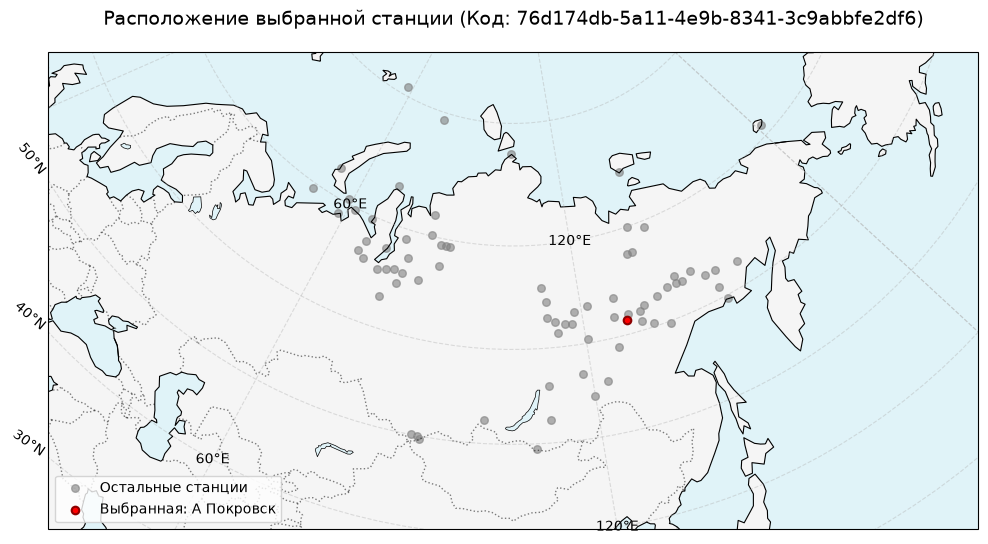

In [185]:
plot_selected_station_on_map(df_stations, selected_code) #запустите ячейку

Вуаля! А теперь попробуем настроить фильтры внутри данных по метеостанции.

### 3.3. Фильтр по дате и глубине

Два самых важных параметра, которые нужно настроить исследователю мнололетних мерзлых грунтов - диапазон дат (временной ряд) и диапазон глубин, на которых производятся измерения с помощью термогирлянд (линия датчиков с интервалами). У поверхности интервалы составляют десятки см, с глубной интервалы увеличиваются до метров. Итак, введём четыре параметра: дата начала, дата окончания, глубина начала, глубина окончания измерений:

In [186]:
def select_parameters():
    """
   Select date and depth ranges for filtering permafrost data 
    using input().
    
    Returns:
    - tuple: (date_start, date_end, depth_min, depth_max)
    """
    print("\n    Настройка параметров фильтрации   ")
    
    # Ввод диапазона дат
    date_start = input("Введите начальную дату (формат YYYY-MM-DD, или оставьте пустым для всех): ").strip()
    date_end = input("Введите конечную дату (формат YYYY-MM-DD, или оставьте пустым для всех): ").strip()
    
    # Ввод диапазона глубин
    depth_min_str = input("Введите минимальную глубину (м, или оставьте пустым): ").strip()
    depth_max_str = input("Введите максимальную глубину (м, или оставьте пустым): ").strip()
    
    # Преобразуем глубины в числа, если они введены
    depth_min = float(depth_min_str) if depth_min_str else None
    depth_max = float(depth_max_str) if depth_max_str else None
    
    # Преобразуем пустые строки в None
    date_start = date_start if date_start else None
    date_end = date_end if date_end else None
    
    print("\nПараметры успешно заданы:")
    print(f"Период: с {date_start if date_start else 'начала'} по {date_end if date_end else 'конца'}")
    print(f"Глубина: от {depth_min if depth_min is not None else 'мин'} до {depth_max if depth_max is not None else 'макс'} м")
    
    return date_start, date_end, depth_min, depth_max

Для примера используйте следующие параметры:

Дата начала: 2025-01-01

Дата окончания: 2026-01-01

Минимальная глубина: 0.1

Максимальная глубина: 10

In [187]:
date_start, date_end, depth_min, depth_max = select_parameters() 


    Настройка параметров фильтрации   


Введите начальную дату (формат YYYY-MM-DD, или оставьте пустым для всех):  2025-01-01
Введите конечную дату (формат YYYY-MM-DD, или оставьте пустым для всех):  2026-01-01
Введите минимальную глубину (м, или оставьте пустым):  0.1
Введите максимальную глубину (м, или оставьте пустым):  10



Параметры успешно заданы:
Период: с 2025-01-01 по 2026-01-01
Глубина: от 0.1 до 10.0 м


**Ура, параметры успешно заданы!**

## 4. Построение графиков температур

### 4.1. График температур

После установки параметров можно построить графики, используя следующую функцию:

In [188]:
def plot_station_temperature(df_long, object_code, date_start=None, date_end=None, depth_min=None, depth_max=None):
    """
    Filter permafrost temperature data for a specific station and date/depth range, 
    and plot temperature time series.
    
    Parameters:
    - df_long (pd.DataFrame): Long-format temperature dataframe.
    - object_code (str): Unique code of the station.
    - date_start (str): Start date for filtering (YYYY-MM-DD).
    - date_end (str): End date for filtering (YYYY-MM-DD).
    - depth_min (float): Minimum depth filter.
    - depth_max (float): Maximum depth filter.
    """
    # Фильтруем данные по коду станции
    df_filtered = df_long[df_long['object_code'] == object_code].copy()
    
    if df_filtered.empty:
        print(f"Нет данных для станции с кодом '{object_code}'.")
        return
    
    # Приводим колонку datetime к типу datetime для корректной фильтрации
    date_col = 'datetime'
    if date_col in df_filtered.columns:
        df_filtered[date_col] = pd.to_datetime(df_filtered[date_col])
        if date_start:
            df_filtered = df_filtered[df_filtered[date_col] >= pd.to_datetime(date_start)]
        if date_end:
            df_filtered = df_filtered[df_filtered[date_col] <= pd.to_datetime(date_end)]
            
    # Фильтрация по глубине (используем depth_m)
    depth_col = 'depth_m'
    if depth_col in df_filtered.columns:
        if depth_min is not None:
            df_filtered = df_filtered[df_filtered[depth_col] >= depth_min]
        if depth_max is not None:
            df_filtered = df_filtered[df_filtered[depth_col] <= depth_max]
            
    if df_filtered.empty:
        print("После применения фильтров по датам и глубине не осталось данных для построения графика.")
        return

    # Строим график
    plt.figure(figsize=(12, 6))
    
    # Значения температуры хранятся в колонкe indicator_value
    val_col = 'indicator_value'
    
    if depth_col in df_filtered.columns:
        for depth, group in df_filtered.groupby(depth_col):
            plt.plot(group[date_col], group[val_col], label=f'Глубина: {depth} м', alpha=0.8)
    else:
        plt.plot(df_filtered[date_col], df_filtered[val_col], color='blue', label='Температура грунта')
        
    plt.axhline(0, color='red', linestyle='--', linewidth=1, label='0°C (граница мерзлоты)')
    plt.title(f'Динамика температуры для станции: {object_code}', fontsize=14)
    plt.xlabel('Дата и время', fontsize=12)
    plt.ylabel('Температура (°C)', fontsize=12)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

Запускаем функцию и получаем результат:

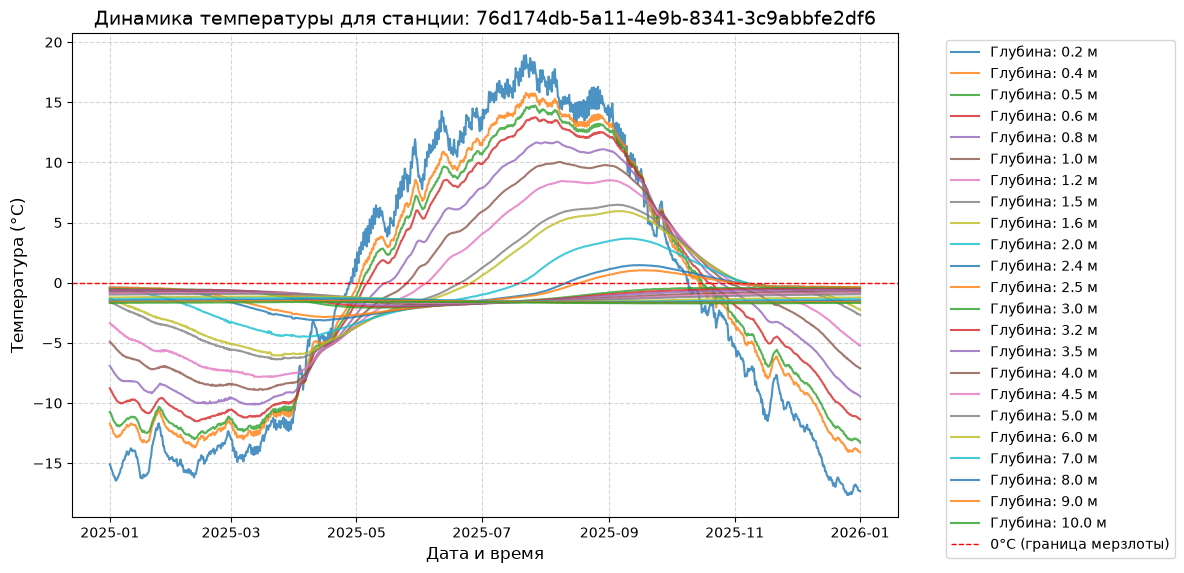

In [189]:
plot_station_temperature(df_long, selected_code, date_start, date_end, depth_min, depth_max)

### 4.2 Бонус: экстремумы

Ещё полезным будет узнать, какие минимальные и максимальные, а также средние температуры фиксировались датчиками за установленный пользователем периодом. Количество наблюдений также укажем. За это отвечает следующая функция:

In [190]:
def calculate_temperature_statistics(df_long, object_code, date_start=None, date_end=None, depth_min=None, depth_max=None):
    """
    Calculate minimum, maximum, and average temperature values for a specific station 
    and selected date/depth range.
    
    Parameters:
    - df_long (pd.DataFrame): Long-format temperature dataframe.
    - object_code (str): Unique code of the station.
    - date_start (str): Start date for filtering (YYYY-MM-DD).
    - date_end (str): End date for filtering (YYYY-MM-DD).
    - depth_min (float): Minimum depth filter.
    - depth_max (float): Maximum depth filter.
    
    Returns:
    - dict: Dictionary containing min, max, and mean temperature values.
    """
    #Фильтруем данные по коду станции
    df_filtered = df_long[df_long['object_code'] == object_code].copy()
    
    if df_filtered.empty:
        print(f"Нет данных для станции с кодом '{object_code}'.")
        return None
    
    #Фильтрация по дате
    date_col = 'datetime'
    if date_col in df_filtered.columns:
        df_filtered[date_col] = pd.to_datetime(df_filtered[date_col])
        if date_start:
            df_filtered = df_filtered[df_filtered[date_col] >= pd.to_datetime(date_start)]
        if date_end:
            df_filtered = df_filtered[df_filtered[date_col] <= pd.to_datetime(date_end)]
            
    #Фильтрация по глубине
    depth_col = 'depth_m'
    if depth_col in df_filtered.columns:
        if depth_min is not None:
            df_filtered = df_filtered[df_filtered[depth_col] >= depth_min]
        if depth_max is not None:
            df_filtered = df_filtered[df_filtered[depth_col] <= depth_max]
            
    if df_filtered.empty:
        print("После применения фильтров по датам и глубине не осталось данных для расчета статистики.")
        return None

    val_col = 'indicator_value'
    
    #Считаем статистики
    min_temp = df_filtered[val_col].min()
    max_temp = df_filtered[val_col].max()
    mean_temp = df_filtered[val_col].mean()
    
    #Выводим результаты
    print(f"\n Статистика температуры для станции: {object_code} ")
    print(f"Минимальная температура: {min_temp:.2f} °C")
    print(f"Максимальная температура: {max_temp:.2f} °C")
    print(f"Средняя температура:     {mean_temp:.2f} °C")
    print(f"Количество измерений:    {len(df_filtered)}")
    
    stats_result = {
        'min_temp': min_temp,
        'max_temp': max_temp,
        'mean_temp': mean_temp,
        'count': len(df_filtered)}
    
    return stats_result

Запускаем функцию, получаем результат:

In [191]:
station_stats = calculate_temperature_statistics(df_long, selected_code, date_start, date_end, depth_min, depth_max)


 Статистика температуры для станции: 76d174db-5a11-4e9b-8341-3c9abbfe2df6 
Минимальная температура: -17.66 °C
Максимальная температура: 18.93 °C
Средняя температура:     -0.94 °C
Количество измерений:    33534


## Вот такая вот штука, учёный! Изучайте многолетние мерзлые грунты (и python) :)

# The End.